# IMDb Movies India - Rating Prediction

**Goal:** predict the IMDb **rating** of an Indian movie from its year, duration, genres, number of votes, director and cast - and find out which of these actually matter.

**Dataset:** `IMDb Movies India.csv` - 15,509 movies with Name, Year, Duration, Genre, Rating, Votes, Director and three lead actors.

**Type of problem:** regression (rating is a number from 1 to 10).

**Plan**
1. Load and clean the messy text columns (`(2019)`, `109 min`, `1,234`, multi-genre strings)
2. Exploratory data analysis
3. Feature engineering: genre flags, director/actor experience and *target-encoded* director/actor quality
4. Compare models with cross-validation, tune the best one, test once
5. Feature-group ablation: how much does each kind of information add?
6. Error analysis and limitations

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, TargetEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_theme(style='whitegrid', palette='deep')
RANDOM_STATE = 42

## 1. Load and clean the data

In [2]:
# The file is not UTF-8 (some names contain accented characters), so it is read as latin-1
raw = pd.read_csv('data/IMDb Movies India.csv', encoding='latin-1')
print('Raw shape:', raw.shape)
raw.head()

Raw shape: (15509, 10)

                                 Name    Year Duration            Genre  Rating Votes            Director       Actor 1             Actor 2          Actor 3
0                                         NaN      NaN            Drama     NaN   NaN       J.S. Randhawa      Manmauji              Birbal  Rajendra Bhatia
1  #Gadhvi (He thought he was Gandhi)  (2019)  109 min            Drama     7.0     8       Gaurav Bakshi  Rasika Dugal      Vivek Ghamande    Arvind Jangid
2                         #Homecoming  (2021)   90 min   Drama, Musical     NaN   NaN  Soumyajit Majumdar  Sayani Gupta   Plabita Borthakur       Roy Angana
3                             #Yaaram  (2019)  110 min  Comedy, Romance     4.4    35          Ovais Khan       Prateik          Ishita Raj  Siddhant Kapoor
4                   ...And Once Again  (2010)  105 min            Drama     NaN   NaN        Amol Palekar  Rajat Kapoor  Rituparna Sengupta      Antara Mali

In [3]:
pd.DataFrame({'missing': raw.isna().sum(), 'missing %': (raw.isna().mean() * 100).round(1), 'dtype': raw.dtypes.astype(str)})

          missing  missing %    dtype
Name            0        0.0      str
Year          528        3.4      str
Duration     8269       53.3      str
Genre        1877       12.1      str
Rating       7590       48.9  float64
Votes        7589       48.9      str
Director      525        3.4      str
Actor 1      1617       10.4      str
Actor 2      2384       15.4      str
Actor 3      3144       20.3      str

Many columns are text that must be turned into numbers. About **49% of the movies have no rating** - they cannot be used to train or test a rating predictor, so they are set aside (they are still useful for counting how many films a director or actor has made).

In [4]:
df = raw.drop_duplicates().copy()
df['Year'] = pd.to_numeric(df['Year'].str.extract(r'(\d{4})')[0])                       # '(2019)'  -> 2019
df['Duration'] = pd.to_numeric(df['Duration'].str.extract(r'(\d+)')[0])                  # '109 min' -> 109
df['Votes'] = pd.to_numeric(df['Votes'].astype(str).str.replace(',', ''), errors='coerce')  # '1,234' -> 1234 ; '$5.16M' (bad row) -> NaN
print('Removed duplicate rows:', len(raw) - len(df))
print('Non-numeric Votes entries turned into NaN:', int((df['Votes'].isna() & raw.loc[df.index, 'Votes'].notna()).sum()), '(e.g. a misplaced "$5.16M")')
df[['Year', 'Duration', 'Votes', 'Rating']].describe().round(2)

Removed duplicate rows: 6
Non-numeric Votes entries turned into NaN: 1 (e.g. a misplaced "$5.16M")

           Year  Duration      Votes   Rating
count  14976.00   7239.00    7919.00  7919.00
mean    1987.01    128.13    1938.52     5.84
std       25.42     28.91   11602.42     1.38
min     1913.00      2.00       5.00     1.10
25%     1968.00    110.00      16.00     4.90
50%     1991.00    131.00      55.00     6.00
75%     2009.00    147.00     404.00     6.80
max     2022.00    321.00  591417.00    10.00

In [5]:
labelled = df.dropna(subset=['Rating']).copy()
print(f'Movies with a rating: {len(labelled):,} of {len(df):,}')
print('Missing values among rated movies:')
labelled.isna().sum()[lambda s: s > 0]

Movies with a rating: 7,919 of 15,503
Missing values among rated movies:

Duration    2068
Genre        102
Director       5
Actor 1      125
Actor 2      200
Actor 3      292
dtype: int64

## 2. Exploratory data analysis

Correlation with rating - log(votes): 0.14, duration: -0.03, year: -0.17

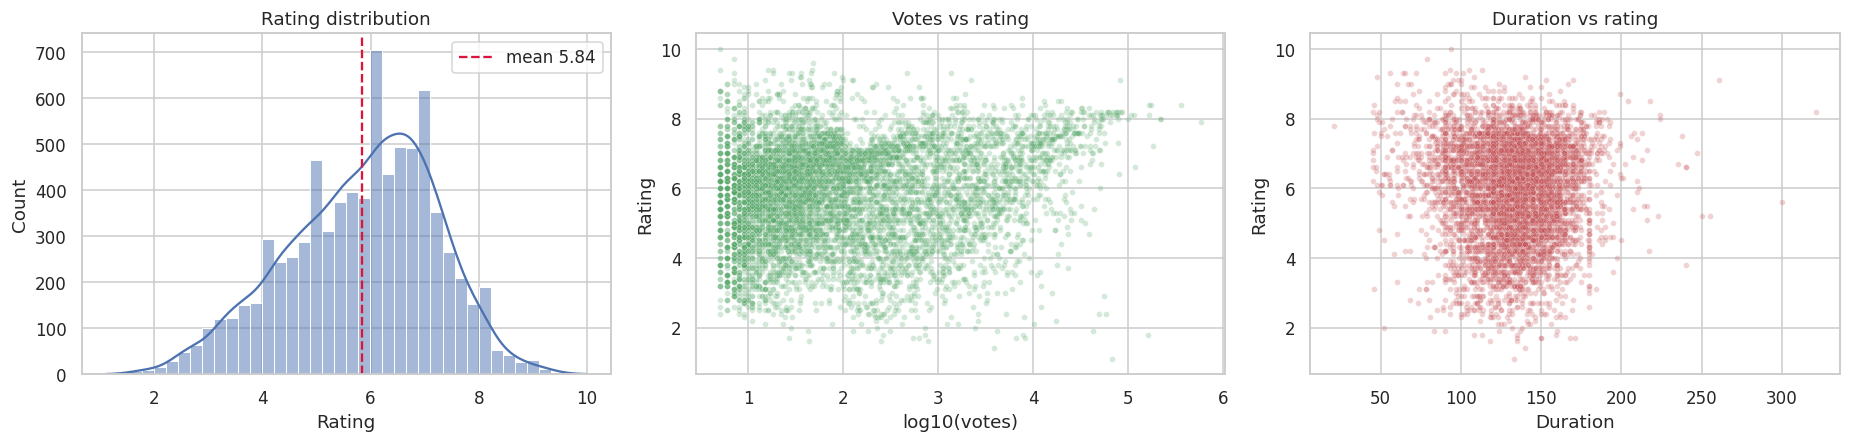

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
sns.histplot(labelled['Rating'], bins=40, kde=True, ax=axes[0], color='#4C72B0')
axes[0].axvline(labelled['Rating'].mean(), color='crimson', ls='--', label=f"mean {labelled['Rating'].mean():.2f}"); axes[0].legend()
axes[0].set_title('Rating distribution')
sns.scatterplot(x=np.log10(labelled['Votes']), y=labelled['Rating'], alpha=.25, s=14, ax=axes[1], color='#55A868')
axes[1].set_xlabel('log10(votes)'); axes[1].set_title('Votes vs rating')
sns.scatterplot(x=labelled['Duration'], y=labelled['Rating'], alpha=.25, s=14, ax=axes[2], color='#C44E52')
axes[2].set_title('Duration vs rating')
plt.tight_layout()
print('Correlation with rating - log(votes): {:.2f}, duration: {:.2f}, year: {:.2f}'.format(
    np.log1p(labelled['Votes']).corr(labelled['Rating']), labelled['Duration'].corr(labelled['Rating']), labelled['Year'].corr(labelled['Rating'])))

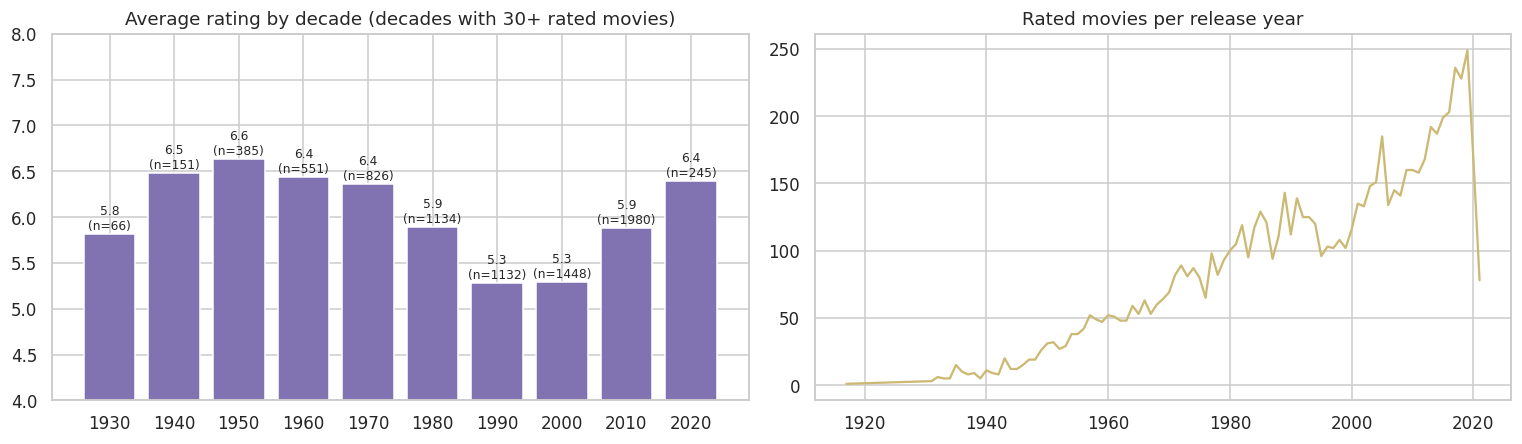

In [7]:
labelled['Decade'] = (labelled['Year'] // 10 * 10).astype('Int64')
dec = labelled.groupby('Decade')['Rating'].agg(['mean', 'count']).query('count >= 30')
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].bar(dec.index.astype(str), dec['mean'], color='#8172B2'); axes[0].set_ylim(4, 8)
axes[0].set_title('Average rating by decade (decades with 30+ rated movies)')
for i, (m, c) in enumerate(zip(dec['mean'], dec['count'])):
    axes[0].text(i, m + .05, f'{m:.1f}\n(n={c})', ha='center', fontsize=8)
per_year = labelled.groupby('Year').size()
axes[1].plot(per_year.index, per_year.values, color='#CCB974'); axes[1].set_title('Rated movies per release year')
plt.tight_layout()

             mean  count
G                       
Documentary  7.61    143
Biography    6.82    142
History      6.80    128
Family       6.20    663
Musical      6.16    498
Unknown      6.00    102

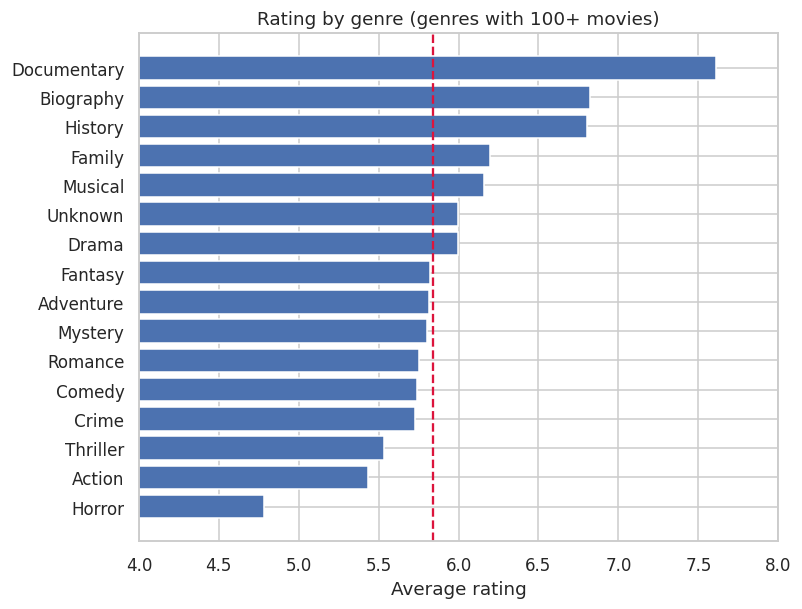

In [8]:
# Average rating by genre (a movie counts once for each of its genres)
g = labelled.assign(G=labelled['Genre'].fillna('Unknown').str.split(', ')).explode('G')
gstats = g.groupby('G')['Rating'].agg(['mean', 'count']).query('count >= 100').sort_values('mean')
plt.figure(figsize=(7.5, 6))
plt.barh(gstats.index, gstats['mean'], color='#4C72B0'); plt.axvline(labelled['Rating'].mean(), color='crimson', ls='--')
plt.xlim(4, 8); plt.xlabel('Average rating'); plt.title('Rating by genre (genres with 100+ movies)')
gstats.sort_values('mean', ascending=False).round(2).head(6)

In [9]:
# Directors and actors: do some people consistently make better-rated films?
for col in ['Director', 'Actor 1']:
    s = labelled.groupby(col)['Rating'].agg(['mean', 'count']).query('count >= 8').sort_values('mean', ascending=False)
    print(f'--- {col}: {len(s)} people with 8+ rated movies. Highest / lowest average rating:')
    print(pd.concat([s.head(4), s.tail(3)]).round(2).to_string()); print()

--- Director: 210 people with 8+ rated movies. Highest / lowest average rating:
                   mean  count
Director                      
Anand Patwardhan   8.29      8
Gulzar             7.52     19
Guru Dutt          7.49      8
Kidar Nath Sharma  7.47      9
Sikander Bharti    4.14     10
Suneel Darshan     4.12      9
Jagdish A. Sharma  3.95     10

--- Actor 1: 166 people with 8+ rated movies. Highest / lowest average rating:
                   mean  count
Actor 1                       
Nargis             7.34     27
Sanjay Mishra      7.28      8
Abhi Bhattacharya  7.15     10
Irrfan Khan        7.14     18
Tusshar Kapoor     4.21     16
Hemant Birje       4.16     14
Bipasha Basu       4.16      9

**Observations** (see the numbers above)
- Ratings are centred on about 5.8 (median 6.0) with a wide spread (std about 1.4) and a long tail of low scores.
- Simple linear relationships are **weak**: log(votes) r = 0.14, release year r = -0.17 (older films tend to be rated higher) and duration r = -0.03. Any predictive power has to come from combinations of features.
- Genre matters: Documentary (7.6), Biography (6.8) and History (6.8) are rated highest on average, while the large Drama, Action and Romance groups sit near the overall mean.
- Individual directors and actors differ a lot in average rating (from about 4 to over 8) - but many have only a handful of movies, so their averages are noisy. That is why we encode them carefully (next section).

## 3. Feature engineering

| Feature group | What it contains |
|---|---|
| **Basics** | `Year`, `Duration` (missing values filled with the median plus a "was missing" flag), number of genres |
| **Genres** | one 0/1 column for every genre with 50+ movies |
| **People experience** | how many films each director / lead actor appears in (counted over the whole catalogue - this uses no ratings) |
| **People quality** | the **target-encoded** average rating of each director / actor. scikit-learn's `TargetEncoder` is *cross-fitted*: the value for a training row is computed from other folds, so a movie's own rating never leaks into its own feature, and rare people are shrunk towards the overall mean |
| **Votes** | `log(1 + Votes)` |

**A caution about Votes:** votes are only known *after* a movie has been out for a while, so a model that uses them cannot predict the rating of an unreleased film. We keep it as an optional group and measure what it adds in the ablation section.

In [10]:
# counts use the whole catalogue (no rating information involved)
counts = {c: df[c].value_counts() for c in ['Director', 'Actor 1', 'Actor 2', 'Actor 3']}
genre_list = [g_ for g_, n in g['G'].value_counts().items() if n >= 50 and g_ != 'Unknown']
print(len(genre_list), 'genres kept:', genre_list)

def build_features(d):
    X = pd.DataFrame(index=d.index)
    X['Year'] = d['Year']
    X['Duration'] = d['Duration']
    X['log_votes'] = np.log1p(d['Votes'])
    genres = d['Genre'].fillna('').str.split(',').apply(lambda lst: [x.strip() for x in lst if x.strip()])
    X['n_genres'] = genres.str.len()
    for gen in genre_list:
        X['g_' + gen] = genres.apply(lambda lst, gen=gen: int(gen in lst))
    for c in counts:
        X[c] = d[c].fillna('Unknown')                                   # to be target-encoded
        X[c + ' films'] = d[c].map(counts[c]).fillna(0).values            # experience
        X.loc[d[c].isna(), c + ' films'] = 0
    return X

X_all = build_features(labelled)
y_all = labelled['Rating']
print('Feature matrix:', X_all.shape)
X_all.iloc[:3, :8]

18 genres kept: ['Drama', 'Action', 'Romance', 'Comedy', 'Crime', 'Thriller', 'Family', 'Musical', 'Adventure', 'Mystery', 'Horror', 'Fantasy', 'Documentary', 'Biography', 'History', 'Animation', 'Music', 'Sport']
Feature matrix: (7919, 30)

     Year  Duration  log_votes  n_genres  g_Drama  g_Action  g_Romance  g_Comedy
1  2019.0     109.0   2.197225         1        1         0          0         0
3  2019.0     110.0   3.583519         2        0         0          1         1
5  1997.0     147.0   6.719013         3        1         0          0         1

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.2, random_state=RANDOM_STATE)
print('Train:', X_train.shape, ' Test:', X_test.shape)

basic = ['Year', 'Duration', 'n_genres']
votes = ['log_votes']
genre_cols = ['g_' + gen for gen in genre_list]
people_cat = ['Director', 'Actor 1', 'Actor 2', 'Actor 3']
people_cnt = [c + ' films' for c in people_cat]

def make_prep(use_votes=True, use_people=True, use_genres=True):
    num = basic + (votes if use_votes else []) + (people_cnt if use_people else [])
    parts = [('num', Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True)), ('scale', StandardScaler())]), num)]
    if use_genres:
        parts.append(('genre', 'passthrough', genre_cols))
    if use_people:
        parts.append(('people', TargetEncoder(target_type='continuous', cv=5, random_state=RANDOM_STATE), people_cat))
    return ColumnTransformer(parts)

Train: (6335, 30)  Test: (1584, 30)

## 4. Model comparison (5-fold cross-validation on the training set)
Baseline = always predict the average rating. R2 = share of the variance in ratings explained; RMSE / MAE are in rating points.

In [12]:
def cv_report(name, pipe, X, y):
    r = cross_validate(pipe, X, y, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE),
                       scoring={'r2': 'r2', 'rmse': 'neg_root_mean_squared_error', 'mae': 'neg_mean_absolute_error'})
    return {'Model': name, 'R2': r['test_r2'].mean(), 'R2 std': r['test_r2'].std(), 'RMSE': -r['test_rmse'].mean(), 'MAE': -r['test_mae'].mean()}

candidates = {
    'Baseline (mean)': DummyRegressor(),
    'Ridge regression': Ridge(alpha=10),
    'Random Forest': RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.4, n_jobs=-1, random_state=RANDOM_STATE),
    'Gradient Boosting': HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, l2_regularization=1.0, random_state=RANDOM_STATE),
}
cv_table = pd.DataFrame([cv_report(n, Pipeline([('prep', make_prep()), ('model', m)]), X_train, y_train) for n, m in candidates.items()]).set_index('Model')
cv_table.round(3)

                      R2  R2 std   RMSE    MAE
Model                                         
Baseline (mean)   -0.001   0.001  1.386  1.129
Ridge regression   0.300   0.013  1.159  0.893
Random Forest      0.391   0.028  1.080  0.826
Gradient Boosting  0.424   0.016  1.051  0.795

## 5. Tune the best model and evaluate once on the test set

In [13]:
grid = {'model__max_iter': [200, 400, 600], 'model__learning_rate': [0.02, 0.04, 0.08], 'model__max_leaf_nodes': [8, 15, 31],
        'model__min_samples_leaf': [10, 20, 40], 'model__l2_regularization': [0.0, 1.0, 5.0]}
search = RandomizedSearchCV(Pipeline([('prep', make_prep()), ('model', HistGradientBoostingRegressor(random_state=RANDOM_STATE))]),
                            grid, n_iter=15, cv=KFold(3, shuffle=True, random_state=RANDOM_STATE), scoring='r2', random_state=RANDOM_STATE)
search.fit(X_train, y_train)
print(f'Best CV R2: {search.best_score_:.3f}')
print({k.replace('model__', ''): v for k, v in search.best_params_.items()})

Best CV R2: 0.415
{'min_samples_leaf': 40, 'max_leaf_nodes': 8, 'max_iter': 600, 'learning_rate': 0.04, 'l2_regularization': 5.0}

In [14]:
best = search.best_estimator_
pred = best.predict(X_test)
test_scores = {'R2': r2_score(y_test, pred), 'RMSE': np.sqrt(mean_squared_error(y_test, pred)), 'MAE': mean_absolute_error(y_test, pred)}
base_pred = np.full(len(y_test), y_train.mean())
print('Test-set results (tuned Gradient Boosting):', {k: round(v, 3) for k, v in test_scores.items()})
print('Baseline (always the training mean):        RMSE = {:.3f}, MAE = {:.3f}'.format(np.sqrt(mean_squared_error(y_test, base_pred)), mean_absolute_error(y_test, base_pred)))

Test-set results (tuned Gradient Boosting): {'R2': 0.447, 'RMSE': np.float64(1.014), 'MAE': 0.769}
Baseline (always the training mean):        RMSE = 1.365, MAE = 1.107

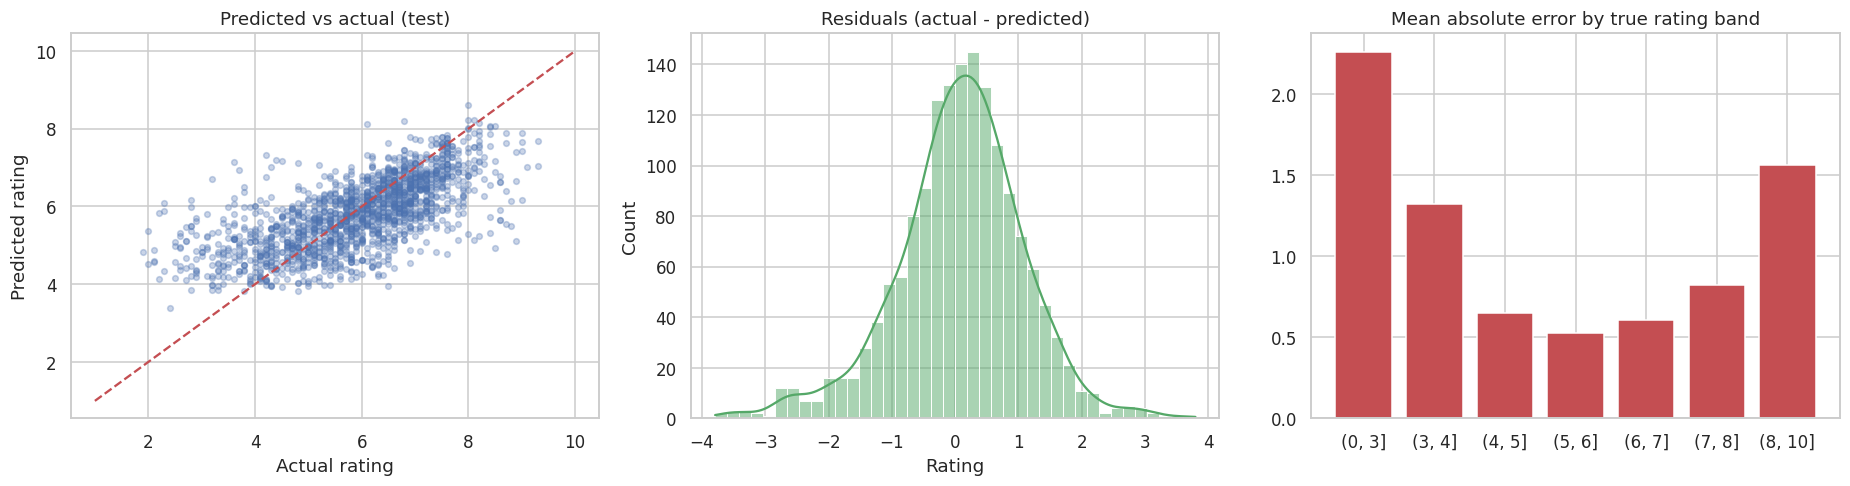

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
axes[0].scatter(y_test, pred, alpha=.3, s=14, color='#4C72B0'); axes[0].plot([1, 10], [1, 10], 'r--')
axes[0].set_xlabel('Actual rating'); axes[0].set_ylabel('Predicted rating'); axes[0].set_title('Predicted vs actual (test)')
resid = y_test - pred
sns.histplot(resid, bins=40, kde=True, ax=axes[1], color='#55A868'); axes[1].set_title('Residuals (actual - predicted)')
bins = pd.cut(y_test, [0, 3, 4, 5, 6, 7, 8, 10])
mae_by = pd.Series(np.abs(resid)).groupby(bins.values).mean()
axes[2].bar([str(i) for i in mae_by.index], mae_by.values, color='#C44E52'); axes[2].set_title('Mean absolute error by true rating band')
plt.tight_layout()

The model is good in the middle of the scale but pulls extreme ratings towards the average (very low and very high scores are under-predicted in magnitude) - typical regression-to-the-mean behaviour for a noisy target.

## 6. Ablation: how much does each kind of information add?
Same model (gradient boosting), 5-fold cross-validation on the training set, adding feature groups one at a time.

In [16]:
steps = [('Year + duration + #genres only', dict(use_votes=False, use_people=False, use_genres=False)),
         ('+ genres', dict(use_votes=False, use_people=False, use_genres=True)),
         ('+ directors & actors', dict(use_votes=False, use_people=True, use_genres=True)),
         ('+ votes (all features)', dict(use_votes=True, use_people=True, use_genres=True)),
         ('Votes only (+ year, duration)', dict(use_votes=True, use_people=False, use_genres=False))]
hgb = lambda: HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, l2_regularization=1.0, random_state=RANDOM_STATE)
abl = pd.DataFrame([cv_report(n, Pipeline([('prep', make_prep(**kw)), ('model', hgb())]), X_train, y_train) for n, kw in steps]).set_index('Model')
abl.round(3)

                                   R2  R2 std   RMSE    MAE
Model                                                      
Year + duration + #genres only  0.136   0.024  1.287  1.007
+ genres                        0.242   0.022  1.206  0.941
+ directors & actors            0.317   0.031  1.144  0.891
+ votes (all features)          0.424   0.016  1.051  0.795
Votes only (+ year, duration)   0.282   0.018  1.173  0.892

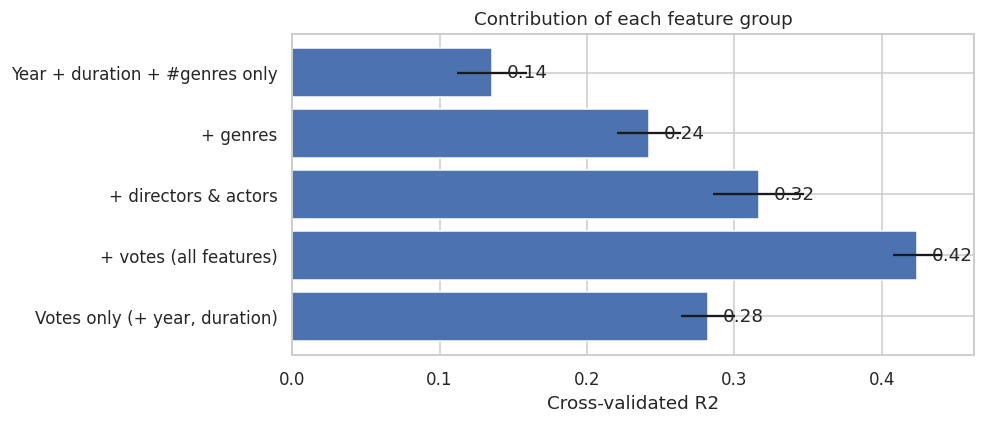

In [17]:
plt.figure(figsize=(8, 3.8))
plt.barh(abl.index[::-1], abl['R2'][::-1], xerr=abl['R2 std'][::-1], color='#4C72B0')
plt.xlabel('Cross-validated R2'); plt.title('Contribution of each feature group')
for i, v in enumerate(abl['R2'][::-1]):
    plt.text(max(v, 0) + .01, i, f'{v:.2f}', va='center')

                           R2 drop
Year                         0.388
Votes                        0.351
Genres                       0.149
Actors (names + #films)      0.130
Directors (name + #films)    0.076
Duration                     0.006

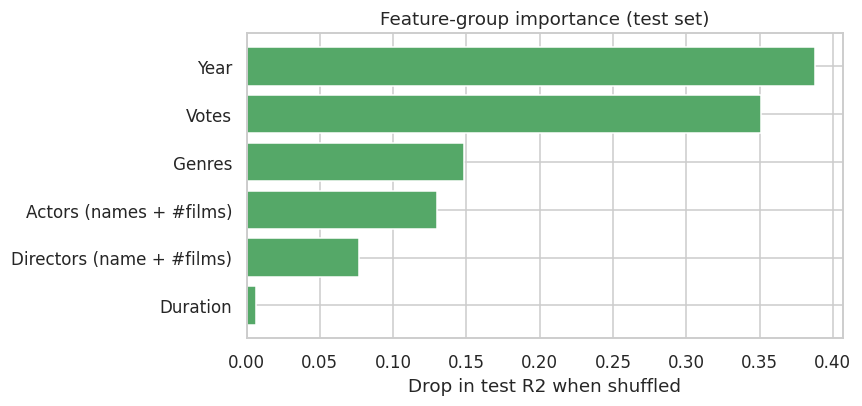

In [18]:
# Importance of each feature group on the test set: shuffle the group's columns together and see how much R2 drops
def group_importance(model, X, y, groups, repeats=10, seed=RANDOM_STATE):
    r = np.random.default_rng(seed)
    base = r2_score(y, model.predict(X))
    out = {}
    for name, cols in groups.items():
        drops = []
        for _ in range(repeats):
            Xp = X.copy()
            Xp[cols] = Xp[cols].iloc[r.permutation(len(Xp))].values
            drops.append(base - r2_score(y, model.predict(Xp)))
        out[name] = np.mean(drops)
    return pd.Series(out).sort_values(ascending=False)

groups = {'Votes': votes, 'Directors (name + #films)': ['Director', 'Director films'],
          'Actors (names + #films)': ['Actor 1', 'Actor 2', 'Actor 3', 'Actor 1 films', 'Actor 2 films', 'Actor 3 films'],
          'Genres': genre_cols + ['n_genres'], 'Year': ['Year'], 'Duration': ['Duration']}
gi = group_importance(best, X_test, y_test, groups)
plt.figure(figsize=(7, 3.6)); plt.barh(gi.index[::-1], gi.values[::-1], color='#55A868')
plt.xlabel('Drop in test R2 when shuffled'); plt.title('Feature-group importance (test set)')
gi.round(3).to_frame('R2 drop')

## 7. Error analysis

In [19]:
errs = pd.DataFrame({'Name': labelled.loc[X_test.index, 'Name'], 'Year': labelled.loc[X_test.index, 'Year'], 'Votes': labelled.loc[X_test.index, 'Votes'],
                     'Actual': y_test, 'Predicted': pred.round(2)})
errs['Error'] = (errs['Actual'] - errs['Predicted']).round(2)
print('Largest over-predictions (model too optimistic):')
print(errs.sort_values('Error').head(5).to_string(index=False))
print('\nLargest under-predictions (model too pessimistic):')
print(errs.sort_values('Error').tail(5).to_string(index=False))

Largest over-predictions (model too optimistic):
                 Name   Year   Votes  Actual  Predicted  Error
                 Boom 2003.0  1361.0     2.3       6.09  -3.79
Student of the Year 2 2019.0 17483.0     2.2       5.82  -3.62
                Clerk 1989.0   126.0     2.3       5.89  -3.59
               Kalank 2019.0 11873.0     3.6       7.15  -3.55
     Veere Di Wedding 2018.0 12000.0     3.2       6.70  -3.50

Largest under-predictions (model too pessimistic):
                   Name   Year  Votes  Actual  Predicted  Error
          Sai Teri Maya 2001.0    5.0     8.4       5.31   3.09
Man on Mission Taqatwar 2005.0   84.0     8.7       5.54   3.16
                 Laadli 2001.0    5.0     8.8       5.51   3.29
                Mazdoor 1934.0    6.0     8.5       4.92   3.58
       Maa Santoshi Maa 2003.0   46.0     8.9       5.10   3.80

In [20]:
# Do errors depend on how popular a movie is? (few votes -> noisy rating)
vote_band = pd.qcut(errs['Votes'], 4, labels=['fewest votes', 'low', 'high', 'most votes'])
errs.assign(abs_error=errs['Error'].abs()).groupby(vote_band)['abs_error'].mean().round(3).to_frame('MAE by vote quartile')

              MAE by vote quartile
Votes                             
fewest votes                 0.857
low                          0.748
high                         0.728
most votes                   0.739

## 8. Predict a new movie

In [21]:
def predict_rating(year, duration, genres, director, actors=('Unknown', 'Unknown', 'Unknown'), votes=1000):
    row = pd.DataFrame([{'Name': 'new', 'Year': year, 'Duration': duration, 'Genre': ', '.join(genres), 'Votes': votes,
                         'Director': director, 'Actor 1': actors[0], 'Actor 2': actors[1], 'Actor 3': actors[2]}])
    return float(best.predict(build_features(row))[0])

print('Drama, 150 min, 2015, 5,000 votes   : {:.2f}'.format(predict_rating(2015, 150, ['Drama', 'Romance'], 'Unknown', votes=5000)))
print('Action, 130 min, 2019, 200 votes    : {:.2f}'.format(predict_rating(2019, 130, ['Action'], 'Unknown', votes=200)))
print('Documentary, 90 min, 2018, 100 votes: {:.2f}'.format(predict_rating(2018, 90, ['Documentary'], 'Unknown', votes=100)))

Drama, 150 min, 2015, 5,000 votes   : 6.24
Action, 130 min, 2019, 200 votes    : 5.77
Documentary, 90 min, 2018, 100 votes: 7.35

## 9. Conclusions

**Data:** 15,503 unique movies, but 49% have no rating, so **7,919 rated movies** are used. Ratings average 5.84 (std 1.38). Duration is missing for 26% of the rated movies and is filled with the median plus a "missing" flag.

**Model performance** (tuned Gradient Boosting, held-out test set of 1,584 movies)
- **R2 = 0.45, RMSE = 1.01, MAE = 0.77 rating points**, versus RMSE 1.37 and MAE 1.11 for always guessing the average. The cross-validated R2 on the training data was about 0.42, consistent with the test result.
- Gradient boosting beat random forest (R2 0.39) and ridge regression (0.30) in cross-validation, i.e. the relationships are non-linear.

**What drives the prediction** (feature-group ablation and test-set importance)
- Cross-validated R2 builds up as information is added: year, duration and number of genres 0.14; plus genres 0.24; plus directors and actors 0.32; plus votes 0.42.
- On the test set, shuffling **Year** costs the most R2 (0.39), then **Votes** (0.35), **Genres** (0.15), **Actors** (0.13) and **Directors** (0.08). Duration contributes almost nothing.
- Without votes the model still reaches R2 of about 0.32, which is the realistic figure for predicting a film's rating *before* it has collected votes.

**Where it fails**
- It compresses the scale: very low ratings (3 and below) have an average error of about 2.3 points and very high ones (8+) about 1.6, versus about 0.5-0.6 for ratings between 4 and 7.
- Big-name releases that critics and audiences disliked (e.g. *Boom*, *Student of the Year 2*, *Kalank*, *Veere Di Wedding*) are over-predicted by about 3.5 points, while obscure titles with only 5-84 votes and ratings of 8.4-8.9 are under-predicted by 3 or more. Ratings based on a handful of votes are inherently noisy.

**Limitations and next steps**
- Roughly half the catalogue is unrated and the metadata contains no budget, box office, release date, language or plot information, which limits how accurate any model can be (R2 stays around 0.4-0.45).
- The split is random, so a director can appear in both training and test sets; a time-based split would test generalisation to new releases.
- Ideas: add text features from the movie title, use the number of films per director/actor in the *past* only, try CatBoost-style categorical handling, and predict a rating *range* instead of a single number.